# Data labeling: how unlabeled voicemail became labeled data

## Contents
1. The taxonomy
2. The annotation guide
3. The AI labeling process
4. The other bucket decision
5. Validation against human labels
6. Labels and file formats
7. The labeled dataset

Scope: the train ready set of 5,881 rows, labeled from transcript text only. This notebook says how unlabeled data was made labeled, which advanced techniques were used, and how the labels were checked. Every number below is computed from the source files in this run.

In [1]:
import json
import pandas as pd
from pathlib import Path
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import Image, display

WS = Path("/home/hatch/workspace/ai-customer-support")
REPO = WS / "smart-voicemail-router"
PREPARED = WS / "dataset" / "prepared"
PREPROCESSED = WS / "dataset" / "preprocessed"
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

def save_fig(fig, fname):
    path = FIGDIR / fname
    FigureCanvasAgg(fig).print_png(str(path))
    return path

def show(fname):
    display(Image(str(FIGDIR / fname)))

def bar(values, labels, title, ylabel, fname, color="#2f6fb2", horizontal=False):
    fig = Figure(figsize=(8, 4.6))
    ax = fig.add_subplot(111)
    if horizontal:
        ax.barh(labels, values, color=color)
        ax.set_title(title)
        ax.set_xlabel(ylabel)
    else:
        ax.bar(labels, values, color=color)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    save_fig(fig, fname)
    show(fname)

lab = pd.read_csv(PREPARED / "labeled_full_v1.csv")
lab_sum = json.loads((PREPARED / "labeling_summary.json").read_text(encoding="utf-8"))
rel = pd.read_csv(PREPARED / "other_relabel.csv")
other_themes = json.loads((PREPARED / "other_themes.json").read_text(encoding="utf-8"))
hz = json.loads((WS / "label-studio-laptop" / "hazem_annotations.json").read_text(encoding="utf-8"))
cal = json.loads((PREPARED / "calibration_batch.json").read_text(encoding="utf-8"))
clean = pd.read_csv(PREPROCESSED / "transcripts_clean.csv")
inv = json.loads((WS / "dataset" / "audio_inventory.json").read_text(encoding="utf-8"))
print("loaded:", len(lab), "labeled rows,", len(rel), "other bucket rows,", len(hz["annotations"]), "Hazem rows,", len(cal), "calibration rows")
print("pandas", pd.__version__)

loaded: 5881 labeled rows, 796 other bucket rows, 4 Hazem rows, 100 calibration rows
pandas 2.1.4


## 1. The taxonomy

The taxonomy is the approved label set. It was built from the data, not imposed on it: TF-IDF plus k-means clustering over the 5,881 normalized transcripts found 10 candidate groups, and the approved taxonomy follows those groups. Hazem approved it on 2026-11-11. After the other bucket work below, the category list has 11 values: greeting_only was dropped (0 rows) and two new categories were added (offers_and_packages, sim_services).

In [2]:
categories = [
    ("network_and_connectivity", "network down, slow internet, no signal, calls dropping"),
    ("billing_and_charges", "bill wrong, charged for services never subscribed to"),
    ("balance_and_data", "balance, data consumption, credit running out"),
    ("app_and_account", "app login, account access, app use problems"),
    ("branch_and_staff", "branch visit, staff behaviour, in store service"),
    ("no_reply_or_long_wait", "no answer, long wait, call never returned"),
    ("cancellation_request", "cancel a service, close an account"),
    ("thanks_or_praise", "thanks, praise, not a complaint"),
    ("offers_and_packages", "package, plan, offer, discount questions and changes (added after clustering)"),
    ("sim_services", "second line, SIM swap, new SIM, lost SIM (added after clustering)"),
    ("other", "none of the above fits"),
]
print("complaint_category (11 values):")
for name, desc in categories:
    print(" ", name, "-", desc)
print()
print("complaint_urgency (3 values, judged from the complaint only, never from tone):")
print("  high - service fully down, money lost, repeated failure")
print("  medium - degraded service or billing dispute")
print("  low - information request, thanks, greeting")
print()
print("customer_state (5 values, from words only):")
print("  calm, frustrated, mad, satisfied, unclear")
print("  mad, satisfied and unclear are Hazem's words. Unclear is his escape hatch when the state cannot be told.")
print()
print("churn_risk (2 values, only on explicit departure language):")
print("  at_risk - caller says they will leave the provider")
print("  not_at_risk - everything else, including cancelling one service alone")
print()
print("greeting_only was dropped: 0 rows. Every greeting was followed by a question or a complaint.")

complaint_category (11 values):
  network_and_connectivity - network down, slow internet, no signal, calls dropping
  billing_and_charges - bill wrong, charged for services never subscribed to
  balance_and_data - balance, data consumption, credit running out
  app_and_account - app login, account access, app use problems
  branch_and_staff - branch visit, staff behaviour, in store service
  no_reply_or_long_wait - no answer, long wait, call never returned
  cancellation_request - cancel a service, close an account
  thanks_or_praise - thanks, praise, not a complaint
  offers_and_packages - package, plan, offer, discount questions and changes (added after clustering)
  sim_services - second line, SIM swap, new SIM, lost SIM (added after clustering)
  other - none of the above fits

complaint_urgency (3 values, judged from the complaint only, never from tone):
  high - service fully down, money lost, repeated failure
  medium - degraded service or billing dispute
  low - information req

## 2. The annotation guide

Guide version 1, approved. The rules that keep labels consistent across annotators and across the AI labeling run.

1. Label from the transcript text only, never from the audio tone for urgency. Urgency comes from the complaint, state comes from the words.
2. If the transcript is too garbled to tell what the issue is, label category other, state unclear, confidence low, and write a note saying so. Do not guess.
3. Churn is only explicit departure language. Cancelling one service is not churn.
4. The gold test set is purely human labeled, never model assisted, never used for training.
5. Calibration first: the team labels the same 100 rows independently, agreement is measured per field with a kappa target of 0.7, the guide is fixed where they disagree, and nothing scales before calibration passes.
6. After the first human batch, a classifier pre-labels the rest and a human verifies and corrects every pre-label. Low confidence rows go to double annotation.

## 3. The AI labeling process

The 5,881 train ready rows were labeled by AZZAR from the transcript text and normalized text, following the guide and the taxonomy. No model was trained. The labeling used the transcript as the only input, one row at a time, with the same rules a human annotator follows. Each row got a category, an urgency, a state, a churn flag, a short note, and a confidence (high or low). Rows whose transcript was too garbled to tell got a best effort label, confidence low, and a note saying so: 219 rows could not be labeled confidently, and 417 rows are low confidence in total.

In [3]:
print("total labeled rows:", len(lab))
print()
print("complaint_category:")
for k, v in lab_sum["complaint_category"].items():
    print(" ", k, v, "(" + str(round(100 * v / len(lab), 1)) + "%)")
print()
print("complaint_urgency:", lab_sum["complaint_urgency"])
print("customer_state:", lab_sum["customer_state"])
print("churn_risk:", lab_sum["churn_risk"])
print("confidence:", lab_sum["confidence"])
print("rows not labeled confidently:", lab_sum["rows_not_labeled_confidently"])
print()
print("Five real labeled rows (file, category, urgency, state, churn, confidence, note):")
for _, r in lab.head(5).iterrows():
    print(" ", r["file"].split("\\")[-1], "|", r["complaint_category"], "|", r["complaint_urgency"], "|", r["customer_state"], "|", r["churn_risk"], "|", r["confidence"], "|", str(r["note"])[:60])

total labeled rows: 5881

complaint_category:
  network_and_connectivity 978 (16.6%)
  other 796 (13.5%)
  billing_and_charges 774 (13.2%)
  balance_and_data 772 (13.1%)
  app_and_account 730 (12.4%)
  thanks_or_praise 705 (12.0%)
  no_reply_or_long_wait 468 (8.0%)
  branch_and_staff 446 (7.6%)
  cancellation_request 212 (3.6%)

complaint_urgency: {'medium': 3396, 'low': 1943, 'high': 542}
customer_state: {'frustrated': 2480, 'calm': 2335, 'satisfied': 709, 'unclear': 197, 'mad': 160}
churn_risk: {'not_at_risk': 5849, 'at_risk': 32}
confidence: {'high': 5464, 'low': 417}
rows not labeled confidently: 219

Five real labeled rows (file, category, urgency, state, churn, confidence, note):
  0001.m4a | billing_and_charges | medium | calm | not_at_risk | high | nan
  0002.m4a | balance_and_data | medium | mad | not_at_risk | high | nan
  0003.m4a | network_and_connectivity | high | frustrated | not_at_risk | high | nan
  0004.m4a | other | low | unclear | not_at_risk | low | transcript too 

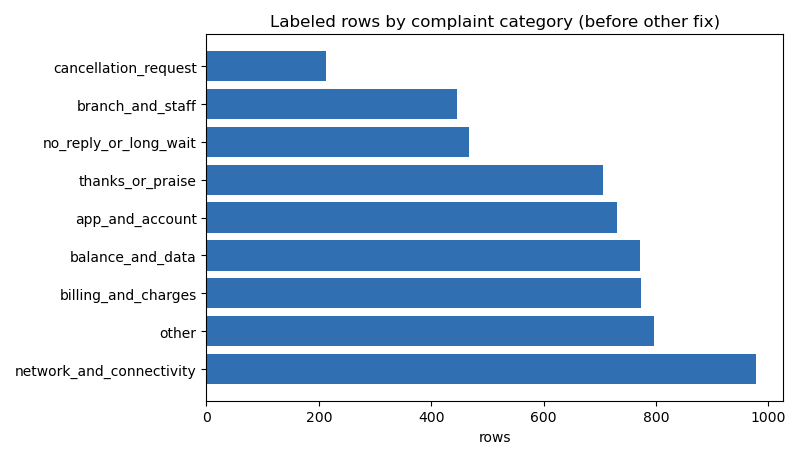

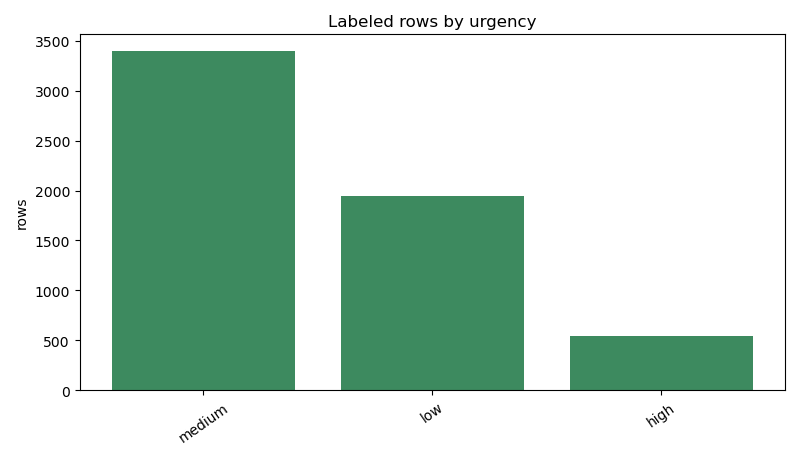

In [4]:
# Charts: category and urgency before the other bucket fix
cat = lab_sum["complaint_category"]
bar(list(cat.values()), list(cat.keys()), "Labeled rows by complaint category (before other fix)", "rows", "category_before.png", horizontal=True)
urg = lab_sum["complaint_urgency"]
bar(list(urg.values()), list(urg.keys()), "Labeled rows by urgency", "rows", "urgency.png", color="#3d8a5f")

## 4. The other bucket decision

Other held 796 rows, 13.5 percent of the labeled set. That is too big for an escape hatch, so the bucket was clustered to find what lives inside it. Technique: TF-IDF (3,000 features, 1 to 2 grams) plus k-means, k from 6 to 12, seed 42, silhouette scored on a fixed 700 row sample. The silhouette scores were all near zero (k=12 best at 0.0368), which means the text does not separate cleanly, so clustering was used only as a discovery aid. Every proposed move was verified by reading the actual transcript text and the annotator note, and false positives were removed.

Decision: add two new categories and re-label 268 rows. Drop greeting_only. Keep 528 rows in other.

- offers_and_packages, 207 rows: package, plan, offer and discount questions, comparisons, activation, renewal, change and switch, including student, family, kids, senior and small business offers, discount eligibility, and promised gifts or cashback never received. Clearly distinct from billing (disputes about charges already incurred) and balance (consumption of credit or data).
- sim_services, 61 rows: second line on the same number, moving a SIM to another device, new SIM activation and delivery, lost SIM blocking failures, SIM not supported or heating, SIM swap errors, two lines on one national ID. Clears the 60 row bar by one row.
- Staying in other, 528 rows: garbled or unclear 151, other mixed 141, spam and harassment 53, vague general complaint 44, loyalty and rewards 39, number porting 30, router and devices 28, payment methods 26, family and children 16. Spam, porting, loyalty and router are coherent but below the 60 row bar. Payment methods overlaps billing.

Measured effect: other shrinks from 796 rows (13.5 percent) to 528 rows (9.0 percent). 268 rows (33.7 percent of the bucket) move to a real category.

In [5]:
print("other bucket rows:", len(rel))
print("new category counts:")
print(rel["new_category"].value_counts().to_dict())
print()
print("Rows moved out of other:", (rel["new_category"] != "other").sum())
print("Rows staying in other:", (rel["new_category"] == "other").sum())
print("Other share before:", round(100 * 796 / len(lab), 1), "%")
print("Other share after:", round(100 * 528 / len(lab), 1), "%")
print()
print("Themes inside other (row counts):")
for k, v in other_themes.items():
    print(" ", k, v["row_count"], "| new category:", v["proposed_new_category"])
print()
print("Three real re-labeled rows (file, theme, new category, note):")
moved = rel[rel["new_category"] != "other"].head(3)
for _, r in moved.iterrows():
    print(" ", r["file"].split("\\")[-1], "|", r["theme"], "|", r["new_category"], "|", str(r["note"])[:70])

other bucket rows: 796
new category counts:
{'other': 528, 'offers_and_packages': 207, 'sim_services': 61}

Rows moved out of other: 268
Rows staying in other: 528
Other share before: 13.5 %
Other share after: 9.0 %

Themes inside other (row counts):
  offers_and_packages 207 | new category: offers_and_packages
  sim_services 61 | new category: sim_services
  number_porting 30 | new category: None
  spam_and_harassment 53 | new category: None
  loyalty_and_rewards 39 | new category: None
  family_and_children 16 | new category: None
  router_and_devices 28 | new category: None
  payment_methods 26 | new category: None
  garbled_or_unclear 151 | new category: None
  vague_general_complaint 44 | new category: None
  other_mixed 141 | new category: None

Three real re-labeled rows (file, theme, new category, note):
  0077.mpeg | sim_services | sim_services | Moved to sim_services: question about getting a second line with the s
  0133.mp4 | offers_and_packages | offers_and_packages | Move

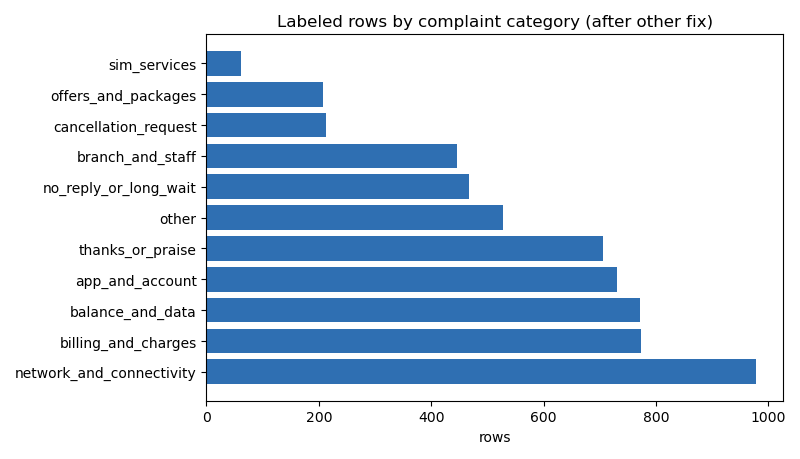

category counts after fix:
{'network_and_connectivity': 978, 'billing_and_charges': 774, 'balance_and_data': 772, 'app_and_account': 730, 'thanks_or_praise': 705, 'other': 528, 'no_reply_or_long_wait': 468, 'branch_and_staff': 446, 'cancellation_request': 212, 'offers_and_packages': 207, 'sim_services': 61}


In [6]:
# Chart: category distribution after the other bucket fix
lab2 = lab.copy()
m = rel.set_index("file")["new_category"]
lab2["complaint_category"] = lab2.apply(
    lambda r: m.get(r["file"], r["complaint_category"]), axis=1)
after = lab2["complaint_category"].value_counts()
bar(list(after.values), list(after.index), "Labeled rows by complaint category (after other fix)", "rows", "category_after.png", horizontal=True)
print("category counts after fix:")
print(after.to_dict())

## 5. Validation against human labels

Two human anchors exist. First, Hazem labeled 4 rows himself on the annotation page (recovered from his phone screenshots). All 4 match the AI labels exactly, field for field. Second, the team is labeling a calibration batch of 100 rows (90 of them are in the train ready set). Once the team finishes, agreement is measured per field with kappa and a 0.7 target, and the AI labels are checked against the human labels. That step is still pending because the team has not finished the 100 rows yet. The gold test set stays purely human labeled and is never used for training.

In [7]:
print("Hazem's 4 rows match the AI labels exactly:", lab_sum["hazem_4_rows_match_exactly"])
print()
print("Hazem's 4 rows (file, category, urgency, state, churn):")
for a in hz["annotations"]:
    print(" ", a["file_id"].split("\\")[-1], "|", a["complaint_category"], "|", a["complaint_urgency"], "|", a["customer_state"], "|", a["churn_risk"])
print()
print("Transcript corrections Hazem made (3):")
for c in hz["transcript_corrections"]:
    print("  row", c.get("row"), ":", str(c.get("original", ""))[:60], "->", str(c.get("corrected", ""))[:60])
print()
print("Calibration batch rows:", len(cal))
print("Calibration rows in train ready set:", lab_sum["calibration_rows_in_train_ready"])
print("Calibration rows labeled by AI:", lab_sum["calibration_rows_labeled"])
print("Kappa per field: PENDING, waiting for the team to finish the 100 rows")
print()
# Verify Hazem's 4 rows match the AI labels field for field
lab_by_file = lab.set_index("file")
ok = 0
for a in hz["annotations"]:
    f = a["file_id"]
    if f in lab_by_file.index:
        r = lab_by_file.loc[f]
        match = (r["complaint_category"] == a["complaint_category"]
                 and r["complaint_urgency"] == a["complaint_urgency"]
                 and r["customer_state"] == a["customer_state"]
                 and r["churn_risk"] == a["churn_risk"])
        ok += int(match)
        print(" row", a["row"], "match:", match)
print("Hazem rows matching exactly:", ok, "of", len(hz["annotations"]))

Hazem's 4 rows match the AI labels exactly: True

Hazem's 4 rows (file, category, urgency, state, churn):
  WhatsApp Audio 2025-12-09 at 4.40.18 PM (1).ogg | network_and_connectivity | low | calm | not_at_risk
  WhatsApp Audio 2025-11-25 at 11.25.14 PM (2).mp4 | billing_and_charges | medium | mad | not_at_risk
  AUDIO-2025-11-27-17-03-55.m4a | other | low | calm | not_at_risk
  0296.mp4 | billing_and_charges | medium | frustrated | at_risk

Transcript corrections Hazem made (3):
  row 1 :  -> 
  row 2 :  -> 
  row 3 :  -> 

Calibration batch rows: 100
Calibration rows in train ready set: 90
Calibration rows labeled by AI: 90
Kappa per field: PENDING, waiting for the team to finish the 100 rows

 row 1 match: True
 row 2 match: True
 row 3 match: True
 row 4 match: True
Hazem rows matching exactly: 4 of 4


## 6. Labels and file formats

The data came from different sources with different file types (m4a, mp4, ogg, mpeg, aac, mp3, wav, opus, ogx). The labeling handles the format difference in one place: labels are derived from the transcript text, and the transcript text comes from the standardized audio (16 kHz mono WAV). The format a file arrived in does not change its label. The check below confirms it: the share of other bucket rows is similar across the big formats, so no format is systematically harder to label. A format that produced far more other rows would have pointed to a transcription problem in that format, not a labeling problem.

In [8]:
# Join labels to inventory to get the format of each labeled row
inv_files = {f["file"]: f["ext"] for f in inv["files"]}
lab_fmt = lab.copy()
lab_fmt["file_norm"] = lab_fmt["file"].str.replace("\\", "/", regex=False)
lab_fmt["ext"] = lab_fmt["file_norm"].map(inv_files)
print("labeled rows with a known format:", lab_fmt["ext"].notna().sum(), "of", len(lab_fmt))
print()
print("Other bucket share by format (rows labeled other / rows in that format):")
for ext, g in lab_fmt.groupby("ext"):
    if len(g) >= 20:
        other_n = (g["complaint_category"] == "other").sum()
        print(" ", ext, len(g), "rows | other:", other_n, "(" + str(round(100 * other_n / len(g), 1)) + "%)")
print()
print("Low confidence share by format:")
for ext, g in lab_fmt.groupby("ext"):
    if len(g) >= 20:
        low_n = (g["confidence"] == "low").sum()
        print(" ", ext, len(g), "rows | low confidence:", low_n, "(" + str(round(100 * low_n / len(g), 1)) + "%)")

labeled rows with a known format: 5878 of 5881

Other bucket share by format (rows labeled other / rows in that format):
  .aac 533 rows | other: 76 (14.3%)
  .m4a 1812 rows | other: 239 (13.2%)
  .mp3 395 rows | other: 46 (11.6%)
  .mp4 1474 rows | other: 198 (13.4%)
  .mpeg 655 rows | other: 84 (12.8%)
  .ogg 969 rows | other: 147 (15.2%)
  .wav 22 rows | other: 5 (22.7%)

Low confidence share by format:
  .aac 533 rows | low confidence: 35 (6.6%)
  .m4a 1812 rows | low confidence: 142 (7.8%)
  .mp3 395 rows | low confidence: 23 (5.8%)
  .mp4 1474 rows | low confidence: 85 (5.8%)
  .mpeg 655 rows | low confidence: 49 (7.5%)
  .ogg 969 rows | low confidence: 83 (8.6%)
  .wav 22 rows | low confidence: 0 (0.0%)


## 7. The labeled dataset

After the other bucket fix, the labeled train ready set has 5,881 rows across 11 categories. The other bucket is 528 rows (9.0 percent). Greeting_only is gone. The 62 included quarantined rows and the 26 recovered files are labeled separately and joined to this set in the preprocessing notebook, which builds the final clean dataset. The team's 100 calibration labels, once finished, validate these AI labels with kappa per field before training.

In [9]:
lab2 = lab.copy()
m = rel.set_index("file")["new_category"]
lab2["complaint_category"] = lab2.apply(
    lambda r: m.get(r["file"], r["complaint_category"]), axis=1)
print("FINAL LABELED TRAIN READY SET (after other fix)")
print("rows:", len(lab2))
print()
print("complaint_category:")
for k, v in lab2["complaint_category"].value_counts().items():
    print(" ", k, v, "(" + str(round(100 * v / len(lab2), 1)) + "%)")
print()
print("complaint_urgency:", lab2["complaint_urgency"].value_counts().to_dict())
print("customer_state:", lab2["customer_state"].value_counts().to_dict())
print("churn_risk:", lab2["churn_risk"].value_counts().to_dict())
print("confidence:", lab2["confidence"].value_counts().to_dict())
print("greeting_only rows:", (lab2["complaint_category"] == "greeting_only").sum())
print("other rows:", (lab2["complaint_category"] == "other").sum())

FINAL LABELED TRAIN READY SET (after other fix)
rows: 5881

complaint_category:
  network_and_connectivity 978 (16.6%)
  billing_and_charges 774 (13.2%)
  balance_and_data 772 (13.1%)
  app_and_account 730 (12.4%)
  thanks_or_praise 705 (12.0%)
  other 528 (9.0%)
  no_reply_or_long_wait 468 (8.0%)
  branch_and_staff 446 (7.6%)
  cancellation_request 212 (3.6%)
  offers_and_packages 207 (3.5%)
  sim_services 61 (1.0%)

complaint_urgency: {'medium': 3396, 'low': 1943, 'high': 542}
customer_state: {'frustrated': 2480, 'calm': 2335, 'satisfied': 709, 'unclear': 197, 'mad': 160}
churn_risk: {'not_at_risk': 5849, 'at_risk': 32}
confidence: {'high': 5464, 'low': 417}
greeting_only rows: 0
other rows: 528
